# Econ 4850 · Economic Analysis with Python
## Lecture 8: Value Function Iteration
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- How the principle of optimality turns an infinite-horizon problem, the cake-eating problem, into a recursive Bellman equation.
- Why the Bellman operator is a contraction, and why iterating on it converges to the value function.
- How to implement fitted value function iteration in Python with a grid, interpolation and numerical maximization, and how to check the result against the analytical solution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar

## The Cake-Eating Problem

- By definition, the solution to a dynamic optimization problem is a sequence of optimal actions. In most cases, we can divide this big problem into smaller subproblems, for example today versus the future, using the principle of optimality suggested by Bellman.

- This insight gives a recursive formulation of the problem, which provides convenient methods for solving complicated problems.

- A standard example of dynamic optimization is the cake-eating problem, in which an agent decides how much cake to eat each period to maximize lifetime utility.

### Problem Setup

- $W_t$ is the size of the remaining cake in period $t$.
- The agent chooses $c_t$, the amount consumed in period $t$.
- The remaining cake evolves as $W_{t+1} = W_t - c_t$.
- The objective is

  $$
  \max_{\{c_t\}_{t=0}^{\infty}} \sum_{t=0}^{\infty} \beta^t u(c_t)
  $$

  subject to $W_{t+1} = W_t - c_t$ and $0 \leq c_t \leq W_t$ for all $t$, with $W_0$ given.

- $\beta \in (0,1)$ is the discount factor.

- $u(c) = \frac{c^{1-\gamma}}{1-\gamma}$, with $\gamma > 0$ and $\gamma \neq 1$ (for $\gamma = 1$, $u(c) = \ln c$).

- The restriction $c_t \geq 0$ is never binding. Why?

- We also call:
  1. $W_t$ the state variable;
  2. $c_t$ the control variable;
  3. $W_{t+1} = W_t - c_t$ the transition function.

- Note that the solution is not trivial: optimal consumption is smooth and decreasing over time. Why?

### A Constrained Optimization Problem

- Note that we cannot solve this problem with the constrained-optimization tools we have learned so far. Why?

- Alternatively, we could "cut the tail", i.e., truncate the problem at some large final period. However, this is very inefficient computationally.

- The good news is that here (and in many other cases) we can apply Bellman's principle of optimality:
    - "An optimal policy has the property that, **regardless of the initial state and initial decision**, the remaining decisions must constitute an optimal policy with regard to the state resulting from the first decision."

## The Value Function

Define the value function $v(x)$ as the maximal lifetime utility attainable from a cake of size $x$:

$$
v(x) = \max_{\{c_t\}_{t=0}^{\infty}} \sum_{t=0}^{\infty} \beta^t u(c_t)
$$

subject to feasibility, $0 \leq c_t \leq W_t$, and the transition $W_{t+1} = W_t - c_t$, with $W_0 = x$. (We write $x$ for the current cake size to match the code below.) The value function can then be written recursively as a **Bellman equation**:

$$
v(x) = \max_{0 \leq c \leq x} \{u(c) + \beta v(x - c)\} \quad \forall x \geq 0.
$$

---
### Digression: Introduction to the Bellman Equation

The **Bellman equation** is a recursive functional equation that expresses the value of an optimization problem at a given state in terms of its value at other states.

If an agent maximizes an objective over time, the Bellman equation represents the **value function** as

$$
V(x) = \max_{a \in A(x)} \left[ u(a) + \beta V(g(x, a)) \right]
$$

where:
- $V(x)$ is the value function at state $x$;
- $A(x)$ is the set of actions feasible at state $x$;
- $u(a)$ is the utility derived from choosing action $a$;
- $\beta \in (0,1)$ is the discount factor;
- $g(x, a)$ is the transition function, which determines next period's state.

In the cake-eating problem, $a = c$, $A(x) = [0, x]$ and $g(x, c) = x - c$.

---

## Solution

- Note that the unknown to be solved for here is the value function. In other words, the solution is a function.

- Once $v(\cdot)$ is known, we can also find $\{c_t\}$. Why?

- Versions of the contraction mapping theorem allow us to compute the solution numerically through a **Bellman operator**.

### The Bellman Operator

- An **operator** is a function that maps elements of one space (here, functions) to another space.

- For example, we have already seen the expectation operator

$$
\mathbb{E}_x f(x,y) = \int f(x,y) \phi(x) \, dx,
$$

where $\phi$ is the density of $x$.

- Here, the Bellman operator $\textcolor{red}{T}$ maps a function $\bar{v}$ to a new function $T\bar{v}$:

$$
\textcolor{red}{T}\bar{v}(x) = \textcolor{red}{\max_{0 \leq c \leq x}\{u(c) + \beta} \, \bar{v}(x \textcolor{red}{- c}) \textcolor{red}{\}}
$$

- The solution, the value function $v(\cdot)$, is then **the fixed point** of this operator:

$$
v(x) = \textcolor{red}{T}v(x) = \textcolor{red}{\max_{0 \leq c \leq x}\{u(c) + \beta} \, v(x \textcolor{red}{- c}) \textcolor{red}{\}} \quad \forall x \geq 0.
$$

### The Contraction Mapping Theorem

- Under some conditions (most importantly $\beta \in (0,1)$), the Bellman operator $T$ is a contraction mapping.
    - An operator $T: V \rightarrow V$ on a metric space $(V, d)$ is a contraction mapping if there exists a modulus $0 \leq \kappa < 1$ such that for all $v_1, v_2 \in V$:
    $$d(T(v_1), T(v_2)) \leq \kappa \, d(v_1, v_2)$$
    For the Bellman operator, the modulus is the discount factor: $\kappa = \beta$.

- Given this, and provided $(V, d)$ is complete, iteratively applying the operator to any initial guess of the value function eventually converges to the solution.
    - The solution is also unique.
    - In other words, your iteration will converge whatever initial guess you start from.

- It helps to build intuition from the scalar case (a contraction from $\mathbb{R}$ to $\mathbb{R}$) before working through the proofs.

### Computation

- Here $W_t$ is a continuous variable, but a computer can only handle finite sets of numbers (i.e., arrays).

- A simple approach is to choose a finite set of grid points and **approximate** the function by its values on the grid.
    - The value function must then be evaluated off the grid points, since $x - c$ is generally not a grid point.
        - We can use interpolation for this, which makes the choice of grid points critical.

- There are many ways to approximate a function with a finite set of parameters.
    - For example, I use deep learning in my own research.

### Algorithm: Fitted Value Function Iteration

1. Set up a grid $x_0, x_1, \dots, x_{N-1}$ for the state (here, the cake size, with $N$ grid points) and the other parameters (here, $\beta$ and $\gamma$).

2. Provide an initial guess of the value function at the grid points, $\{v^0_0, v^0_1, \dots, v^0_{N-1}\}$, and set $n = 0$.

3. Build a function $\hat{v}^n$ by interpolating $\{v^n_0, v^n_1, \dots, v^n_{N-1}\}$, to be used inside the Bellman operator $T$.

4. Apply $T$ at each grid point to get

$$
\{v^{n+1}_0, v^{n+1}_1, \dots, v^{n+1}_{N-1}\} = \{T\hat{v}^n(x_0), T\hat{v}^n(x_1), \dots, T\hat{v}^n(x_{N-1})\}.
$$

5. Use a stopping rule (e.g., the sup norm $\max_i |v^{n+1}_i - v^n_i|$ below a tolerance) to decide whether $v^n$ and $v^{n+1}$ are close.
    - If yes, return $v^{n+1}$ as the solution.
    - If no, set $n \leftarrow n + 1$ and return to step 3.

## Coding

The code follows [QuantEcon](https://python.quantecon.org/cake_eating_numerical.html).

In [2]:
def maximize(g, a, b, args):
    """
    Maximize the function g over the interval [a, b].

    We use the fact that the maximizer of g on any interval is
    also the minimizer of -g. The tuple args collects any extra
    arguments to g.

    Returns the maximizer and the maximal value.
    """

    def objective(x):
        return -g(x, *args)

    result = minimize_scalar(objective, bounds=(a, b), method="bounded")
    maximizer, maximum = result.x, -result.fun
    return maximizer, maximum

In [3]:
class CakeEating:

    def __init__(self,
                 β=0.96,           # discount factor
                 γ=1.5,            # degree of relative risk aversion
                 x_grid_min=1e-3,  # exclude zero for numerical stability
                 x_grid_max=2.5,   # largest cake size on the grid
                 x_grid_size=120):

        self.β, self.γ = β, γ

        # Set up grid
        self.x_grid = np.linspace(x_grid_min, x_grid_max, x_grid_size)

    # Utility function
    def u(self, c):

        γ = self.γ

        if γ == 1:
            return np.log(c)
        else:
            return (c ** (1 - γ)) / (1 - γ)

    # First derivative of the utility function
    def u_prime(self, c):

        return c ** (-self.γ)

    def state_action_value(self, c, x, v_array):
        """
        Right-hand side of the Bellman equation given x and c.
        """

        u, β = self.u, self.β
        # Value of the remaining cake x - c, interpolated from the grid values
        v_next = np.interp(x - c, self.x_grid, v_array)

        return u(c) + β * v_next

In [4]:
def T(v, ce):
    """
    The Bellman operator. Updates the guess of the value function.

    * ce is an instance of CakeEating
    * v is an array representing a guess of the value function

    """
    v_new = np.empty_like(v)

    for i, x in enumerate(ce.x_grid):
        # Maximize the RHS of the Bellman equation at state x
        v_new[i] = maximize(ce.state_action_value, 1e-10, x, (x, v))[1]

    return v_new

In [5]:
ce = CakeEating()

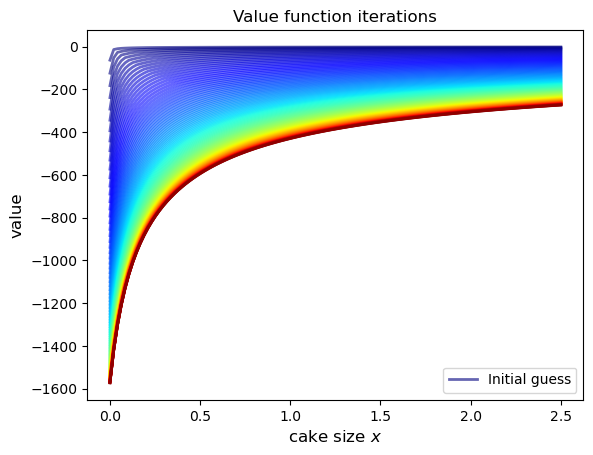

In [6]:
x_grid = ce.x_grid
v = ce.u(x_grid)  # Initial guess
n_iter = 120      # Number of iterations

fig, ax = plt.subplots()

ax.plot(x_grid, v, color=plt.cm.jet(0),
        lw=2, alpha=0.6, label="Initial guess")

for i in range(n_iter):
    v = T(v, ce)  # Apply the Bellman operator
    ax.plot(x_grid, v, color=plt.cm.jet(i / n_iter), lw=2, alpha=0.6)

ax.legend()
ax.set_ylabel("value", fontsize=12)
ax.set_xlabel("cake size $x$", fontsize=12)
ax.set_title("Value function iterations")

plt.show()

Now iterate until the sup-norm distance between successive guesses falls below a tolerance, as in step 5 of the algorithm.

In [7]:
def compute_value_function(ce,
                           tol=1e-4,
                           max_iter=1000,
                           verbose=True,
                           print_skip=25):

    # Set up loop
    v = np.zeros(len(ce.x_grid))  # Initial guess
    i = 0
    error = tol + 1

    while i < max_iter and error > tol:
        v_new = T(v, ce)

        error = np.max(np.abs(v - v_new))  # sup norm
        i += 1

        if verbose and i % print_skip == 0:
            print(f"Error at iteration {i} is {error}.")

        v = v_new

    if error > tol:
        print("Failed to converge!")
    elif verbose:
        print(f"\nConverged in {i} iterations.")

    return v_new

In [8]:
v = compute_value_function(ce)

Error at iteration 25 is 23.8003755134813.


Error at iteration 50 is 8.577577195046615.


Error at iteration 75 is 3.091330659691039.


Error at iteration 100 is 1.1141054204751981.


Error at iteration 125 is 0.4015199357729671.


...

Error at iteration 225 is 0.006773769545588948.


Error at iteration 250 is 0.0024412443051460286.


Error at iteration 275 is 0.0008798164326435653.


Error at iteration 300 is 0.00031708295398402697.


Error at iteration 325 is 0.00011427565573285392.

Converged in 329 iterations.


With [some algebra](https://python.quantecon.org/cake_eating_problem.html) (see the exercise in the QuantEcon lecture), one can derive the analytical solution for the optimal consumption policy and the value function:

$$
c^*(x) = \left(1 - \beta^{1/\gamma}\right) x, \qquad
v^*(x) = \left(1 - \beta^{1/\gamma}\right)^{-\gamma} \frac{x^{1-\gamma}}{1-\gamma}.
$$

In [9]:
def c_star(x, β, γ):

    return (1 - β ** (1/γ)) * x


def v_star(x, β, γ):

    return (1 - β**(1 / γ))**(-γ) * (x**(1-γ) / (1-γ))

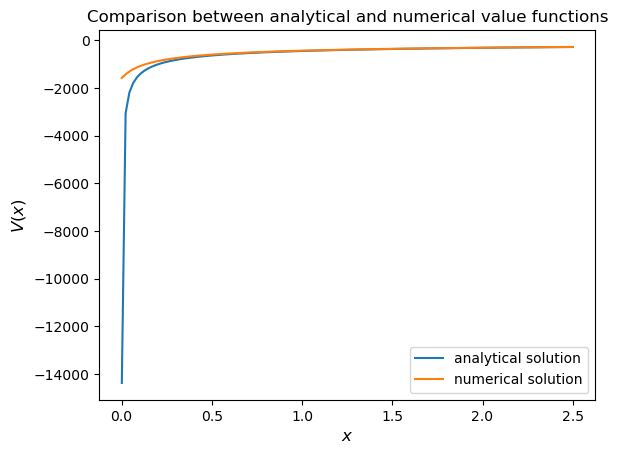

In [10]:
v_analytical = v_star(ce.x_grid, ce.β, ce.γ)

fig, ax = plt.subplots()

ax.plot(x_grid, v_analytical, label="analytical solution")
ax.plot(x_grid, v, label="numerical solution")
ax.set_ylabel("$V(x)$", fontsize=12)
ax.set_xlabel("$x$", fontsize=12)
ax.legend()
ax.set_title("Comparison between analytical and numerical value functions")
plt.show()

## Some Notes on the Bellman Operator

1. If some of the states are random, the value function becomes

    $$
    v(x) = \max_{\{a_t\}_{t=0}^{\infty}} \mathbb{E}_0 \sum_{t=0}^{\infty} \beta^t u(a_t, x_t), \quad a_t \in A(x_t), \quad x_0 = x,
    $$

    and the Bellman equation becomes

    $$
    v(x) = \max_{a \in A(x)} \left\{ u(a, x) + \beta \, \mathbb{E}\left[v(x') \mid x, a\right] \right\}.
    $$

    - The expectation can be computed easily by Monte Carlo, and the Bellman operator is still a contraction mapping.

2. If agents live for a finite number of periods, up to a final period $\bar{T}$, the Bellman equation becomes

    $$
    v(x, t) = \max_{a \in A(x)} \left\{ u(a, x) + \beta \, \mathbb{E}\left[v(x', t+1) \mid x, a\right] \right\}.
    $$

    - Since finding the value $v(\cdot, \bar{T})$ in the final period is a static problem, we can use **backward induction** to calculate $v(\cdot, t)$ for all $t \in \{0, 1, 2, \dots, \bar{T}-1\}$, using a `for` loop to apply the Bellman operator.